# Практическая работа №4
## Разработка и обучение нейронной сети для решения прикладной задачи

**Вариант 38:** AI-система юридической поддержки  
**Студент:** Пак А.В., группа ИС 242 (4)_2  
**Задача:** классификация юридических запросов по четырём категориям.

### Цель работы
Разработать и обучить нейронную сеть LSTM для тематической классификации юридических запросов, оценить качество по метрикам Accuracy, Precision, Recall и macro F1, визуализировать обучение и исследовать влияние гиперпараметров.

In [1]:
from pathlib import Path
import copy, math, re
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix)

RANDOM_STATE = 42
LABELS = ['Трудовое право', 'Семейное право', 'Жилищное право', 'Защита прав потребителей']
SHORT_LABELS = ['Трудовое', 'Семейное', 'Жилищное', 'Потребители']
TOKEN_PATTERN = re.compile(r'[а-яёa-z0-9]+', flags=re.IGNORECASE)
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid', font='DejaVu Sans')
print('Библиотеки загружены. RANDOM_STATE =', RANDOM_STATE)

Библиотеки загружены. RANDOM_STATE = 42


In [2]:
DATA_PATH = Path('PR4_Pak_Artur_legal_dataset.csv')
if not DATA_PATH.exists():
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        pass
if not DATA_PATH.exists():
    raise FileNotFoundError('Загрузите PR4_Pak_Artur_legal_dataset.csv')
df = pd.read_csv(DATA_PATH)
df = df[['id', 'text', 'category']].dropna().drop_duplicates().reset_index(drop=True)
print('Размер датасета:', df.shape)
print('Пропуски:', int(df.isna().sum().sum()))
print('Дубликаты текстов:', int(df['text'].duplicated().sum()))
print(df['category'].value_counts().reindex(LABELS))

Размер датасета: (320, 3)
Пропуски: 0
Дубликаты текстов: 0
category
Трудовое право              80
Семейное право              80
Жилищное право              80
Защита прав потребителей    80


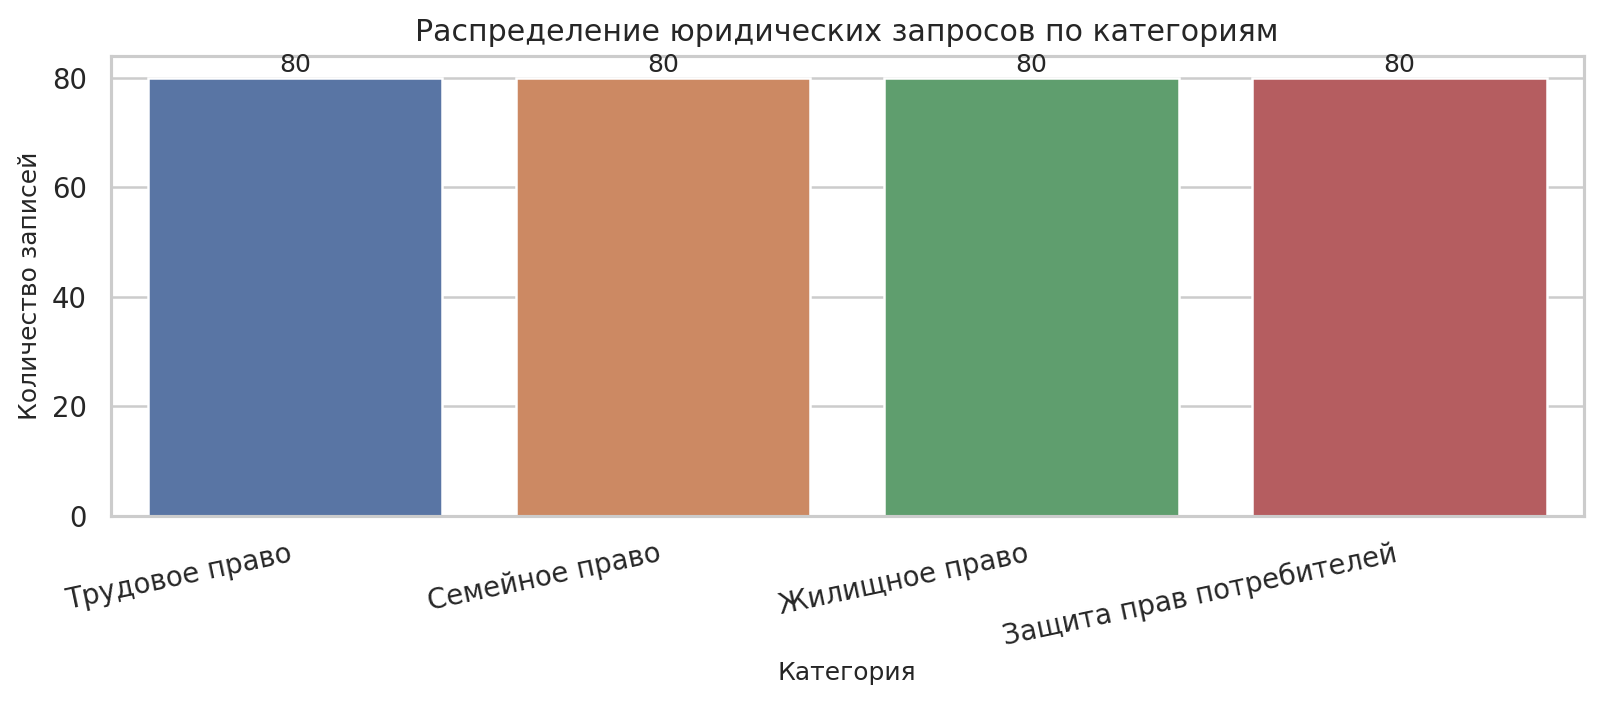

In [3]:
counts = df['category'].value_counts().reindex(LABELS)
plt.figure(figsize=(9, 4))
ax = sns.barplot(x=counts.index, y=counts.values, hue=counts.index, legend=False)
for index, value in enumerate(counts.values):
    ax.text(index, value + 1, str(value), ha='center')
plt.title('Распределение юридических запросов по категориям')
plt.ylabel('Количество записей'); plt.xlabel('Категория')
plt.xticks(rotation=12, ha='right'); plt.tight_layout(); plt.show()

In [4]:
def tokenize(text: str) -> list[str]:
    return TOKEN_PATTERN.findall(str(text).lower())


def build_vocabulary(texts: pd.Series, max_words: int = 1800) -> dict[str, int]:
    counts = Counter(token for text in texts for token in tokenize(text))
    vocabulary = {"<PAD>": 0, "<UNK>": 1}
    for token, _ in counts.most_common(max_words - 2):
        vocabulary[token] = len(vocabulary)
    return vocabulary


def encode_texts(texts: pd.Series | list[str], vocabulary: dict[str, int], max_len: int) -> np.ndarray:
    result = np.zeros((len(texts), max_len), dtype=np.int32)
    for row_index, text in enumerate(texts):
        ids = [vocabulary.get(token, 1) for token in tokenize(text)[:max_len]]
        result[row_index, : len(ids)] = ids
    return result


train_df, temp_df = train_test_split(df, test_size=0.30, random_state=RANDOM_STATE, stratify=df['category'])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=RANDOM_STATE, stratify=temp_df['category'])
vocabulary = build_vocabulary(train_df['text'], max_words=1800)
MAX_LEN = 43
label_to_id = {label: index for index, label in enumerate(LABELS)}
X_train = encode_texts(train_df['text'].reset_index(drop=True), vocabulary, MAX_LEN)
X_val = encode_texts(val_df['text'].reset_index(drop=True), vocabulary, MAX_LEN)
X_test = encode_texts(test_df['text'].reset_index(drop=True), vocabulary, MAX_LEN)
y_train = train_df['category'].map(label_to_id).to_numpy()
y_val = val_df['category'].map(label_to_id).to_numpy()
y_test = test_df['category'].map(label_to_id).to_numpy()
print('Train / validation / test:', len(X_train), len(X_val), len(X_test))
print('Размер словаря:', len(vocabulary), '| MAX_LEN:', MAX_LEN)

Train / validation / test: 224 48 48
Размер словаря: 627 | MAX_LEN: 43


### Архитектура
Модель реализует последовательность **Embedding → LSTM → Dropout → Dense(Softmax)**. Для оптимизации используется Adam, функция потерь — категориальная кросс-энтропия, градиенты ограничиваются по глобальной норме.

In [5]:
def sigmoid(values: np.ndarray) -> np.ndarray:
    values = np.clip(values, -30.0, 30.0)
    return 1.0 / (1.0 + np.exp(-values))


def softmax(values: np.ndarray) -> np.ndarray:
    shifted = values - values.max(axis=1, keepdims=True)
    exponent = np.exp(shifted)
    return exponent / exponent.sum(axis=1, keepdims=True)


class NumpyLSTMClassifier:
    """Small educational LSTM: Embedding -> LSTM -> Dropout -> Dense."""

    def __init__(
        self,
        vocab_size: int,
        embedding_dim: int,
        hidden_dim: int,
        n_classes: int,
        dropout: float,
        learning_rate: float,
        seed: int = 42,
    ) -> None:
        self.rng = np.random.default_rng(seed)
        self.embedding_dim = embedding_dim
        self.hidden_dim = hidden_dim
        self.dropout = dropout
        self.learning_rate = learning_rate
        joined = embedding_dim + hidden_dim
        gate_scale = math.sqrt(2.0 / (joined + hidden_dim))
        dense_scale = math.sqrt(2.0 / (hidden_dim + n_classes))
        self.params = {
            "E": self.rng.normal(0.0, 0.08, (vocab_size, embedding_dim)).astype(np.float64),
            "Wf": self.rng.normal(0.0, gate_scale, (joined, hidden_dim)),
            "Wi": self.rng.normal(0.0, gate_scale, (joined, hidden_dim)),
            "Wo": self.rng.normal(0.0, gate_scale, (joined, hidden_dim)),
            "Wg": self.rng.normal(0.0, gate_scale, (joined, hidden_dim)),
            "bf": np.ones(hidden_dim) * 0.5,
            "bi": np.zeros(hidden_dim),
            "bo": np.zeros(hidden_dim),
            "bg": np.zeros(hidden_dim),
            "Wy": self.rng.normal(0.0, dense_scale, (hidden_dim, n_classes)),
            "by": np.zeros(n_classes),
        }
        self.params["E"][0] = 0.0
        self.m = {name: np.zeros_like(value) for name, value in self.params.items()}
        self.v = {name: np.zeros_like(value) for name, value in self.params.items()}
        self.step = 0

    def forward(self, x_ids: np.ndarray, training: bool = False):
        p = self.params
        batch_size, sequence_length = x_ids.shape
        h = np.zeros((batch_size, self.hidden_dim))
        c = np.zeros_like(h)
        recurrent_cache = []

        for time_index in range(sequence_length):
            ids = x_ids[:, time_index]
            mask = (ids != 0).astype(np.float64)[:, None]
            x = p["E"][ids]
            z = np.concatenate([x, h], axis=1)
            f = sigmoid(z @ p["Wf"] + p["bf"])
            i = sigmoid(z @ p["Wi"] + p["bi"])
            o = sigmoid(z @ p["Wo"] + p["bo"])
            g = np.tanh(z @ p["Wg"] + p["bg"])
            c_candidate = f * c + i * g
            h_candidate = o * np.tanh(c_candidate)
            recurrent_cache.append((ids, mask, z, f, i, o, g, c.copy(), c_candidate))
            h = mask * h_candidate + (1.0 - mask) * h
            c = mask * c_candidate + (1.0 - mask) * c

        if training and self.dropout > 0:
            keep_probability = 1.0 - self.dropout
            dropout_mask = (self.rng.random(h.shape) < keep_probability) / keep_probability
        else:
            dropout_mask = np.ones_like(h)
        h_drop = h * dropout_mask
        logits = h_drop @ p["Wy"] + p["by"]
        probabilities = softmax(logits)
        return probabilities, (recurrent_cache, h_drop, dropout_mask)

    def loss_and_gradients(self, x_ids: np.ndarray, y: np.ndarray):
        probabilities, cache = self.forward(x_ids, training=True)
        recurrent_cache, h_drop, dropout_mask = cache
        batch_size = len(y)
        loss = -np.log(probabilities[np.arange(batch_size), y] + 1e-12).mean()

        d_logits = probabilities.copy()
        d_logits[np.arange(batch_size), y] -= 1.0
        d_logits /= batch_size
        gradients = {name: np.zeros_like(value) for name, value in self.params.items()}
        gradients["Wy"] = h_drop.T @ d_logits
        gradients["by"] = d_logits.sum(axis=0)
        d_h_next = (d_logits @ self.params["Wy"].T) * dropout_mask
        d_c_next = np.zeros_like(d_h_next)

        for ids, mask, z, f, i, o, g, c_previous, c_candidate in reversed(recurrent_cache):
            d_h_candidate = d_h_next * mask
            d_h_identity = d_h_next * (1.0 - mask)
            d_c_candidate = d_c_next * mask
            d_c_identity = d_c_next * (1.0 - mask)

            tanh_c = np.tanh(c_candidate)
            d_o = d_h_candidate * tanh_c
            d_c_total = d_c_candidate + d_h_candidate * o * (1.0 - tanh_c**2)
            d_f = d_c_total * c_previous
            d_i = d_c_total * g
            d_g = d_c_total * i
            d_c_previous = d_c_total * f

            d_af = d_f * f * (1.0 - f)
            d_ai = d_i * i * (1.0 - i)
            d_ao = d_o * o * (1.0 - o)
            d_ag = d_g * (1.0 - g**2)

            gradients["Wf"] += z.T @ d_af
            gradients["Wi"] += z.T @ d_ai
            gradients["Wo"] += z.T @ d_ao
            gradients["Wg"] += z.T @ d_ag
            gradients["bf"] += d_af.sum(axis=0)
            gradients["bi"] += d_ai.sum(axis=0)
            gradients["bo"] += d_ao.sum(axis=0)
            gradients["bg"] += d_ag.sum(axis=0)

            d_z = (
                d_af @ self.params["Wf"].T
                + d_ai @ self.params["Wi"].T
                + d_ao @ self.params["Wo"].T
                + d_ag @ self.params["Wg"].T
            )
            d_x = d_z[:, : self.embedding_dim]
            d_h_gate = d_z[:, self.embedding_dim :]
            np.add.at(gradients["E"], ids, d_x * mask)
            d_h_next = d_h_identity + d_h_gate
            d_c_next = d_c_identity + d_c_previous

        gradients["E"][0] = 0.0
        total_norm = math.sqrt(sum(float((grad**2).sum()) for grad in gradients.values()))
        if total_norm > 5.0:
            scale = 5.0 / (total_norm + 1e-12)
            gradients = {name: grad * scale for name, grad in gradients.items()}
        return loss, gradients

    def update(self, gradients: dict[str, np.ndarray]) -> None:
        self.step += 1
        beta1, beta2 = 0.9, 0.999
        for name, gradient in gradients.items():
            self.m[name] = beta1 * self.m[name] + (1.0 - beta1) * gradient
            self.v[name] = beta2 * self.v[name] + (1.0 - beta2) * (gradient**2)
            m_hat = self.m[name] / (1.0 - beta1**self.step)
            v_hat = self.v[name] / (1.0 - beta2**self.step)
            self.params[name] -= self.learning_rate * m_hat / (np.sqrt(v_hat) + 1e-8)
        self.params["E"][0] = 0.0

    def predict_proba(self, x_ids: np.ndarray) -> np.ndarray:
        return self.forward(x_ids, training=False)[0]

    def predict(self, x_ids: np.ndarray) -> np.ndarray:
        return self.predict_proba(x_ids).argmax(axis=1)


def evaluate(model: NumpyLSTMClassifier, x_ids: np.ndarray, y: np.ndarray) -> dict[str, float]:
    probabilities = model.predict_proba(x_ids)
    prediction = probabilities.argmax(axis=1)
    loss = float(-np.log(probabilities[np.arange(len(y)), y] + 1e-12).mean())
    precision, recall, f1, _ = precision_recall_fscore_support(
        y, prediction, average="macro", zero_division=0
    )
    return {
        "loss": loss,
        "accuracy": float(accuracy_score(y, prediction)),
        "precision_macro": float(precision),
        "recall_macro": float(recall),
        "f1_macro": float(f1),
    }


def train_model(
    x_train: np.ndarray,
    y_train: np.ndarray,
    x_val: np.ndarray,
    y_val: np.ndarray,
    vocab_size: int,
    config: dict,
    seed: int,
):
    model = NumpyLSTMClassifier(
        vocab_size=vocab_size,
        embedding_dim=config["embedding_dim"],
        hidden_dim=config["hidden_dim"],
        n_classes=len(LABELS),
        dropout=config["dropout"],
        learning_rate=config["learning_rate"],
        seed=seed,
    )
    rng = np.random.default_rng(seed)
    history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": [], "val_f1": []}
    best_parameters = copy.deepcopy(model.params)
    best_val_f1 = -1.0
    best_epoch = 0
    patience_left = config["patience"]

    for epoch in range(config["epochs"]):
        indices = rng.permutation(len(x_train))
        for start in range(0, len(indices), config["batch_size"]):
            batch_indices = indices[start : start + config["batch_size"]]
            _, gradients = model.loss_and_gradients(x_train[batch_indices], y_train[batch_indices])
            model.update(gradients)

        train_metrics = evaluate(model, x_train, y_train)
        val_metrics = evaluate(model, x_val, y_val)
        history["loss"].append(train_metrics["loss"])
        history["accuracy"].append(train_metrics["accuracy"])
        history["val_loss"].append(val_metrics["loss"])
        history["val_accuracy"].append(val_metrics["accuracy"])
        history["val_f1"].append(val_metrics["f1_macro"])

        if val_metrics["f1_macro"] > best_val_f1 + 1e-5:
            best_val_f1 = val_metrics["f1_macro"]
            best_epoch = epoch + 1
            best_parameters = copy.deepcopy(model.params)
            patience_left = config["patience"]
        else:
            patience_left -= 1
            if patience_left == 0:
                break

    model.params = best_parameters
    return model, history, best_epoch, evaluate(model, x_val, y_val)


Класс NumpyLSTMClassifier и функции обучения определены.


In [6]:
CONFIGURATIONS = [{'name': 'A', 'embedding_dim': 16, 'hidden_dim': 24, 'dropout': 0.2, 'learning_rate': 0.004, 'batch_size': 32, 'epochs': 24, 'patience': 6}, {'name': 'B', 'embedding_dim': 24, 'hidden_dim': 40, 'dropout': 0.3, 'learning_rate': 0.003, 'batch_size': 32, 'epochs': 28, 'patience': 7}, {'name': 'C', 'embedding_dim': 32, 'hidden_dim': 56, 'dropout': 0.45, 'learning_rate': 0.0015, 'batch_size': 16, 'epochs': 32, 'patience': 8}]
experiment_rows = []
trained = {}
for index, config in enumerate(CONFIGURATIONS):
    model, history, best_epoch, val_metrics = train_model(
        X_train, y_train, X_val, y_val, len(vocabulary), config, RANDOM_STATE + index)
    trained[config['name']] = (model, history)
    experiment_rows.append({
        'name': config['name'], 'best_epoch': best_epoch,
        'val_accuracy': val_metrics['accuracy'], 'val_f1_macro': val_metrics['f1_macro']})
experiments = pd.DataFrame(experiment_rows).sort_values('val_f1_macro', ascending=False)
print(experiments.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

C: best_epoch=17, val_accuracy=0.854, val_f1=0.855
A: best_epoch=23, val_accuracy=0.854, val_f1=0.852
B: best_epoch=13, val_accuracy=0.833, val_f1=0.831


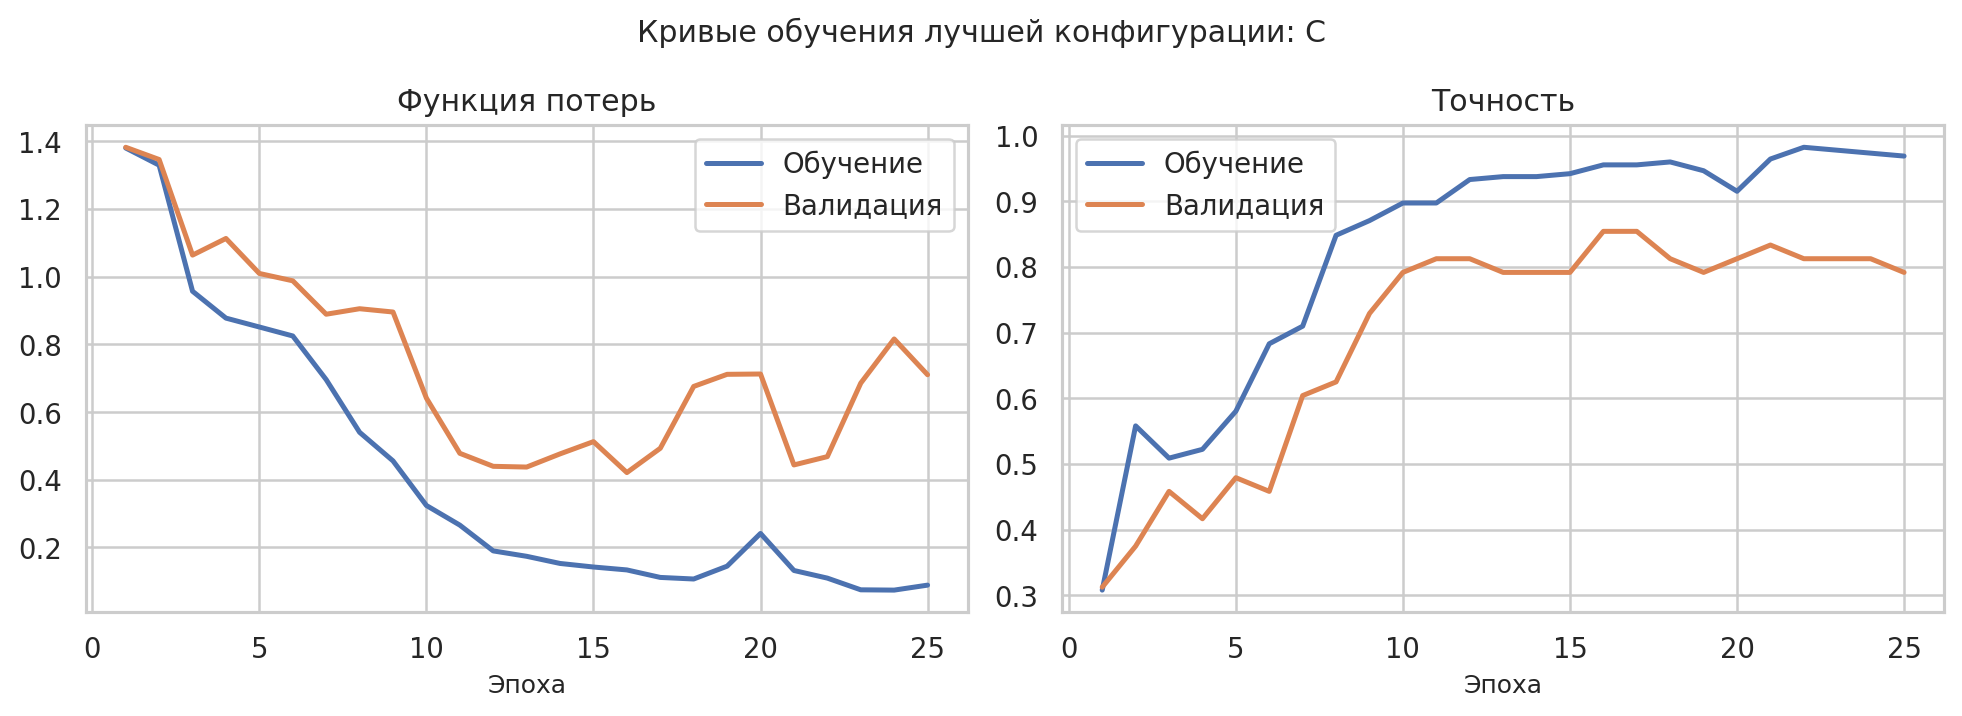

In [7]:
best_name = experiments.iloc[0]['name']
best_model, best_history = trained[best_name]
epochs = np.arange(1, len(best_history['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(epochs, best_history['loss'], label='Обучение')
axes[0].plot(epochs, best_history['val_loss'], label='Валидация')
axes[0].set_title('Функция потерь'); axes[0].set_xlabel('Эпоха'); axes[0].legend()
axes[1].plot(epochs, best_history['accuracy'], label='Обучение')
axes[1].plot(epochs, best_history['val_accuracy'], label='Валидация')
axes[1].set_title('Точность'); axes[1].set_xlabel('Эпоха'); axes[1].legend()
fig.suptitle(f'Кривые обучения лучшей конфигурации: {best_name}')
plt.tight_layout(); plt.show()

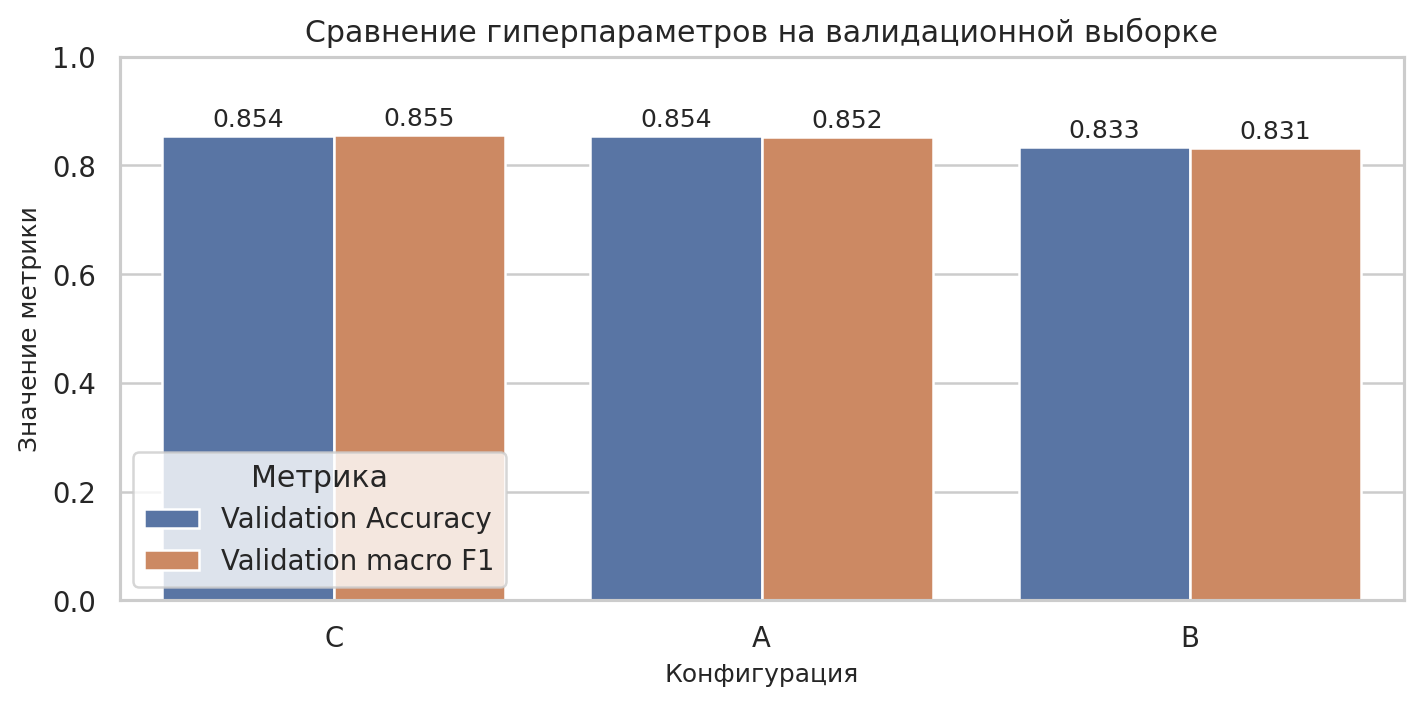

In [8]:
plot_df = experiments.melt(id_vars=['name'], value_vars=['val_accuracy', 'val_f1_macro'], var_name='Метрика', value_name='Значение')
plt.figure(figsize=(8, 4))
sns.barplot(data=plot_df, x='name', y='Значение', hue='Метрика')
plt.ylim(0, 1.0); plt.title('Сравнение гиперпараметров на валидации')
plt.xlabel('Конфигурация'); plt.ylabel('Значение'); plt.tight_layout(); plt.show()

In [9]:
test_probabilities = best_model.predict_proba(X_test)
test_prediction = test_probabilities.argmax(axis=1)
print('Лучшая конфигурация:', best_name)
print(classification_report(y_test, test_prediction, target_names=LABELS, digits=3, zero_division=0))

Лучшая конфигурация: C
                          precision    recall  f1-score   support

          Трудовое право      0.818     0.750     0.783        12
          Семейное право      1.000     0.750     0.857        12
          Жилищное право      0.688     0.917     0.786        12
Защита прав потребителей      0.833     0.833     0.833        12

                accuracy                          0.812        48
               macro avg      0.835     0.812     0.815        48
            weighted avg      0.835     0.812     0.815        48



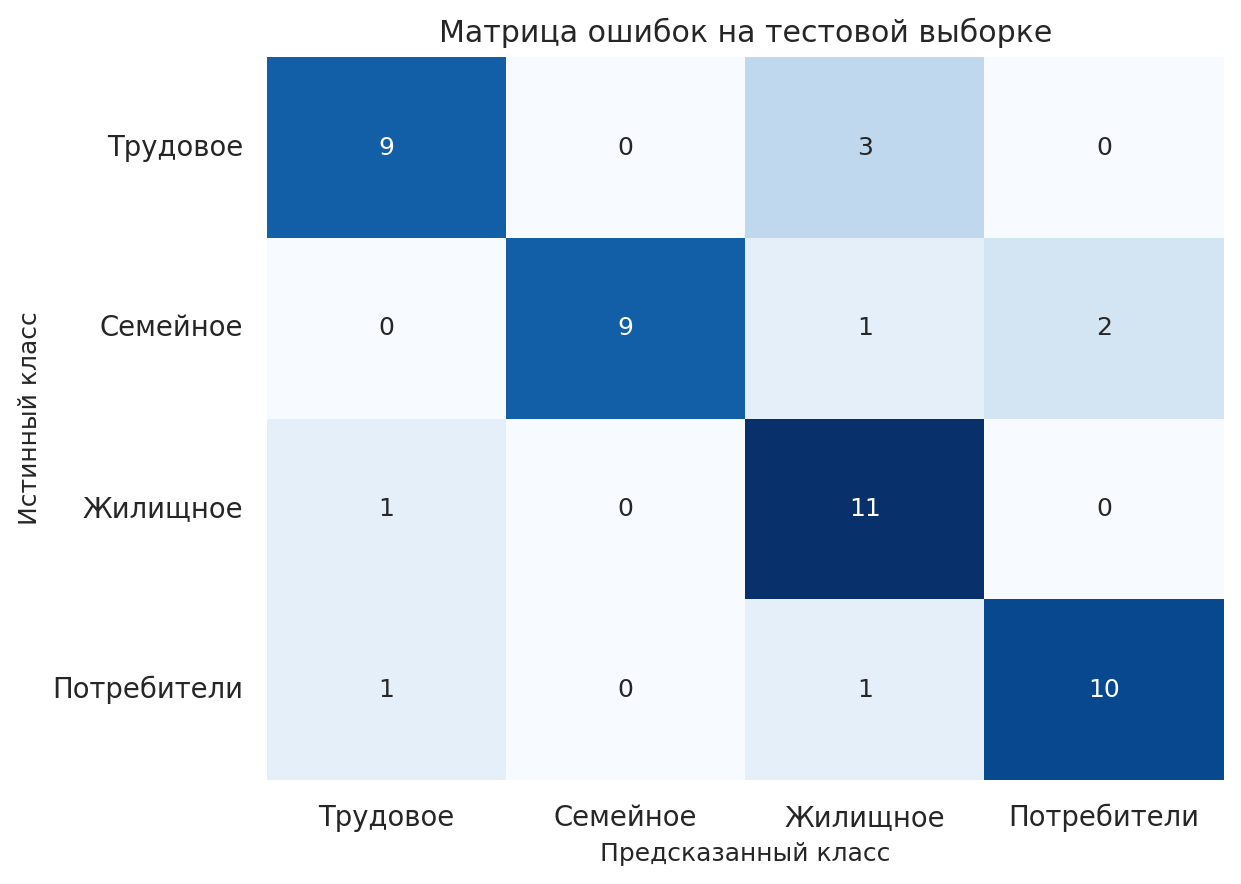

In [10]:
matrix = confusion_matrix(y_test, test_prediction, labels=np.arange(len(LABELS)))
plt.figure(figsize=(7, 5))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', xticklabels=SHORT_LABELS, yticklabels=SHORT_LABELS)
plt.title('Матрица ошибок на тестовой выборке')
plt.xlabel('Предсказанный класс'); plt.ylabel('Истинный класс')
plt.tight_layout(); plt.show()

In [11]:
examples = [
    'Работодатель задерживает зарплату и отказывается выдать расчётный лист.',
    'После развода второй родитель не перечисляет алименты на ребёнка.',
    'Арендодатель требует освободить квартиру до окончания договора аренды.',
    'Магазин отказался вернуть деньги за неисправный ноутбук по гарантии.',
]
example_ids = encode_texts(examples, vocabulary, MAX_LEN)
example_probabilities = best_model.predict_proba(example_ids)
for number, (text_value, probability) in enumerate(zip(examples, example_probabilities), 1):
    predicted_id = int(probability.argmax())
    print(f'{number}. {LABELS[predicted_id]} (p={probability[predicted_id]:.3f}) — {text_value}')

1. Трудовое право (p=0.532) — Работодатель задерживает зарплату и отказывается выдать расчётный лист.
2. Семейное право (p=0.558) — После развода второй родитель не перечисляет алименты на ребёнка.
3. Жилищное право (p=0.338) — Арендодатель требует освободить квартиру до окончания договора аренды.
4. Защита прав потребителей (p=0.720) — Магазин отказался вернуть деньги за неисправный ноутбук по гарантии.


### Вывод
Лучшей стала конфигурация **C**. На тестовой выборке она получила Accuracy = **0.812** и macro F1 = **0.815**. Эксперимент показал, что увеличение числа скрытых нейронов не гарантирует улучшение на небольшом датасете: качество определяется совместно размерностью представления, регуляризацией, скоростью обучения и моментом ранней остановки.